In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "font.size": 10})
SEED = 2026
print("NumPy:", np.__version__, "| Random seed:", SEED)

NumPy: 2.5.5 | Random seed: 2026


In [2]:
MODULATION = "BPSK"    # "BPSK" or "QPSK"
TRAIN_SYMBOLS = 5000      # known symbols for adaptive training
TEST_SYMBOLS = 12000      # unseen symbols for unbiased evaluation
SNR_DB = 18.0            # measured against channel output signal power
NUM_TAPS = 11            # number of LMS FIR weights
DECISION_DELAY = 4       # target is transmitted symbol s[n - D]
MU = 0.015               # LMS adaptation step size
CHANNEL = np.array([0.9, 0.50, -0.30], dtype=complex)
assert MODULATION in {"BPSK", "QPSK"}
assert 0 <= DECISION_DELAY < NUM_TAPS
assert TRAIN_SYMBOLS >= NUM_TAPS + DECISION_DELAY
assert MU > 0 and TEST_SYMBOLS > 0
print(f"{MODULATION}, {NUM_TAPS} taps, delay={DECISION_DELAY}, mu={MU}, SNR={SNR_DB} dB")

BPSK, 11 taps, delay=4, mu=0.015, SNR=18.0 dB


In [3]:
def generate_symbols(modulation, count, rng):
    if modulation == "BPSK":
        bits = rng.integers(0, 2, size=count, dtype=np.int8)
        symbols = (2 * bits - 1).astype(complex)
    elif modulation == "QPSK":
        bits = rng.integers(0, 2, size=(count, 2), dtype=np.int8)
        symbols = ((2 * bits[:, 0] - 1) + 1j * (2 * bits[:, 1] - 1)) / np.sqrt(2)
    else:
        raise ValueError("Modulation must be BPSK or QPSK")
    return bits, symbols

rng_demo = np.random.default_rng(SEED)
bits_demo, symbols_demo = generate_symbols(MODULATION, 12, rng_demo)
print("Transmitted bits:\n", bits_demo)
print("Mapped symbols:\n", symbols_demo)

Transmitted bits:
 [1 1 0 1 0 1 1 0 1 0 1 0]
Mapped symbols:
 [ 1.+0.j  1.+0.j -1.+0.j  1.+0.j -1.+0.j  1.+0.j  1.+0.j -1.+0.j  1.+0.j
 -1.+0.j  1.+0.j -1.+0.j]


In [4]:
def channel_fir(symbols, channel):
    return np.convolve(symbols, channel, mode="full")[:len(symbols)]

example_tx = np.array([1., -1., 1., 1., -1.], dtype=complex)
example_channel_out = channel_fir(example_tx, CHANNEL)
print("Channel h =", CHANNEL)
print("Example symbols =", example_tx)
print("Output with ISI =", example_channel_out)

Channel h = [ 0.9+0.j  0.5+0.j -0.3+0.j]
Example symbols = [ 1.+0.j -1.+0.j  1.+0.j  1.+0.j -1.+0.j]
Output with ISI = [ 0.9+0.j -0.4+0.j  0.1+0.j  1.7+0.j -0.7+0.j]


In [5]:
def add_awgn(clean_signal, snr_db, rng, real_noise=False):
    signal_power = np.mean(np.abs(clean_signal)**2)
    noise_power = signal_power / (10 ** (snr_db / 10))
    if real_noise:
        noise = np.sqrt(noise_power) * rng.standard_normal(len(clean_signal))
    else:
        noise = np.sqrt(noise_power / 2) * (
            rng.standard_normal(len(clean_signal)) + 1j*rng.standard_normal(len(clean_signal)))
    return clean_signal + noise

print("Example noisy samples:", np.round(add_awgn(example_channel_out, SNR_DB, np.random.default_rng(SEED)), 3))

Example noisy samples: [ 0.834-0.024j -0.38 -0.026j -0.058+0.025j  1.816-0.022j -0.647-0.019j]


In [6]:
def tapped_input(samples, n, num_taps):
    return samples[n - np.arange(num_taps)]

print("Example 3-tap window at index 3:", tapped_input(np.arange(10), 3, 3))

Example 3-tap window at index 3: [3 2 1]


In [7]:
def train_lms(received, transmitted, train_symbols, taps, delay, mu):
    if len(received) != len(transmitted):
        raise ValueError("Received and transmitted arrays must be the same length")
    if taps < 1 or delay < 0 or delay >= taps:
        raise ValueError("Use taps>=1 and 0 <= delay < taps")
    if train_symbols <= taps or train_symbols > len(transmitted):
        raise ValueError("Training interval is invalid")
    w = np.zeros(taps, dtype=complex)
    w[delay] = 1.0 + 0j  # initial through-path; not equalized yet
    errors, weights = [], []
    for n in range(max(taps - 1, delay), train_symbols + delay):
        if n >= len(received):
            break
        x = tapped_input(received, n, taps)
        desired = transmitted[n - delay]
        estimated = np.vdot(w, x)  # w^H x
        error = desired - estimated
        w += mu * x * np.conj(error)  # complex LMS
        if not np.all(np.isfinite(w)):
            raise FloatingPointError("LMS diverged: reduce MU")
        errors.append(abs(error) ** 2)
        weights.append(w.copy())
    return w, np.asarray(errors), np.asarray(weights)

print("LMS training function defined.")

LMS training function defined.


In [8]:
def decide_symbols(values, modulation):
    signs_re = np.where(np.real(values) >= 0, 1, -1)
    if modulation == "BPSK":
        return signs_re.astype(complex)
    if modulation == "QPSK":
        signs_im = np.where(np.imag(values) >= 0, 1, -1)
        return (signs_re + 1j * signs_im) / np.sqrt(2)
    raise ValueError("Unsupported modulation")

def bits_from_symbols(symbols, modulation):
    re = (np.real(symbols) >= 0).astype(np.int8)
    if modulation == "BPSK":
        return re
    return np.column_stack([re, (np.imag(symbols) >= 0).astype(np.int8)])

def ber_from_symbols(reference, estimates, modulation):
    a = bits_from_symbols(reference, modulation)
    b = bits_from_symbols(decide_symbols(estimates, modulation), modulation)
    return np.count_nonzero(a != b) / a.size

print("Decision functions defined.")

Decision functions defined.


In [9]:
def simulate(modulation="BPSK", snr_db=18, mu=0.015, taps=11, delay=4,
             channel=None, train_symbols=5000, test_symbols=12000, seed=2026):
    if channel is None:
        channel = np.array([0.9, 0.50, -0.30], dtype=complex)
    channel = np.asarray(channel, dtype=complex)
    if abs(channel[0]) == 0:
        raise ValueError("Baseline requires nonzero leading channel coefficient")
    if delay >= taps or delay < 0 or taps > train_symbols:
        raise ValueError("Choose taps > delay >= 0 and taps <= training symbols")
    if not np.allclose(channel.imag, 0) and modulation == "BPSK":
        # complex baseband may be used with BPSK as well
        pass
    rng = np.random.default_rng(seed)
    _, transmitted = generate_symbols(modulation, train_symbols + test_symbols, rng)
    clean = channel_fir(transmitted, channel)
    received = add_awgn(clean, snr_db, rng, real_noise=np.allclose(channel.imag, 0) and modulation == "BPSK")
    weights, mse_history, weight_history = train_lms(
        received, transmitted, train_symbols, taps, delay, mu)
    k = np.arange(train_symbols, train_symbols + test_symbols)
    n = k + delay
    valid = n < len(received)
    k, n = k[valid], n[valid]
    reference = transmitted[k]
    equalized = np.array([np.vdot(weights, tapped_input(received, int(i), taps)) for i in n])
    baseline = received[k] / channel[0]
    return dict(modulation=modulation, snr_db=snr_db, mu=mu, taps=taps, delay=delay,
                transmitted=transmitted, received=received, channel=channel,
                reference=reference, baseline=baseline, equalized=equalized,
                weights=weights, weight_history=weight_history,
                mse_history=mse_history,
                ber_before=ber_from_symbols(reference, baseline, modulation),
                ber_after=ber_from_symbols(reference, equalized, modulation),
                mse_test_before=np.mean(abs(reference - baseline)**2),
                mse_test_after=np.mean(abs(reference - equalized)**2),
                num_test_symbols=len(reference))

result = simulate(MODULATION, SNR_DB, MU, NUM_TAPS, DECISION_DELAY,
                  CHANNEL, TRAIN_SYMBOLS, TEST_SYMBOLS, SEED)
print(f"Evaluated symbols: {result['num_test_symbols']:,}")
print(f"BER before equalization: {result['ber_before']:.6g}")
print(f"BER after equalization:  {result['ber_after']:.6g}")
print(f"Test MSE before: {result['mse_test_before']:.5f}")
print(f"Test MSE after:  {result['mse_test_after']:.5f}")

Evaluated symbols: 11,996
BER before equalization: 0.0556852
BER after equalization:  8.33611e-05
Test MSE before: 0.43942
Test MSE after:  0.07733


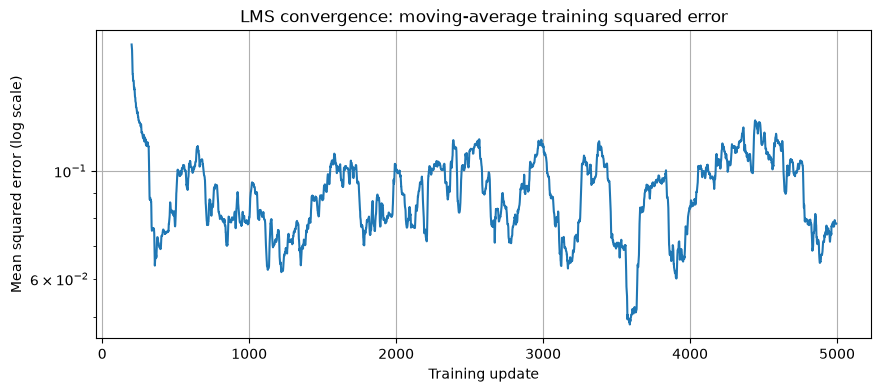

Mean of first 300 errors: 0.14368779082267877
Mean of last 300 errors: 0.07171379544826012


In [10]:
loss = result["mse_history"]
window = min(200, max(1, len(loss) // 10))
smoothed = np.convolve(loss, np.ones(window)/window, mode="valid")
fig, ax = plt.subplots()
ax.semilogy(np.arange(len(smoothed)) + window, np.maximum(smoothed, 1e-9))
ax.set(title="LMS convergence: moving-average training squared error",
       xlabel="Training update", ylabel="Mean squared error (log scale)")
plt.show()
print("Mean of first 300 errors:", np.mean(loss[:300]))
print("Mean of last 300 errors:", np.mean(loss[-300:]))

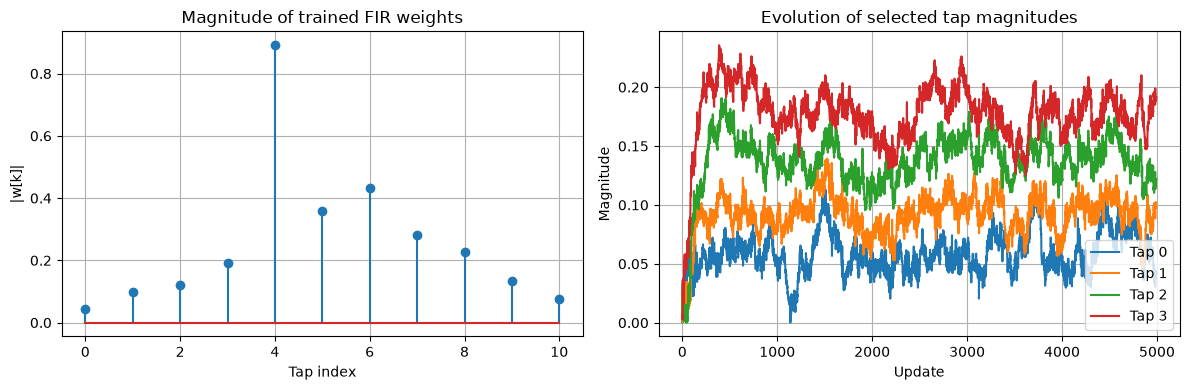

Final LMS weights: [-0.0435+0.j  0.0975+0.j -0.1216+0.j  0.1913+0.j  0.8912+0.j -0.3575+0.j
  0.4338+0.j -0.2821+0.j  0.226 +0.j -0.1333+0.j  0.0748+0.j]


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].stem(np.arange(NUM_TAPS), np.abs(result["weights"]))
axs[0].set(title="Magnitude of trained FIR weights", xlabel="Tap index", ylabel="|w[k]|")
for j in range(min(4, NUM_TAPS)):
    axs[1].plot(np.abs(result["weight_history"][:, j]), label=f"Tap {j}")
axs[1].set(title="Evolution of selected tap magnitudes", xlabel="Update", ylabel="Magnitude")
axs[1].legend()
plt.tight_layout(); plt.show()
print("Final LMS weights:", np.round(result["weights"], 4))

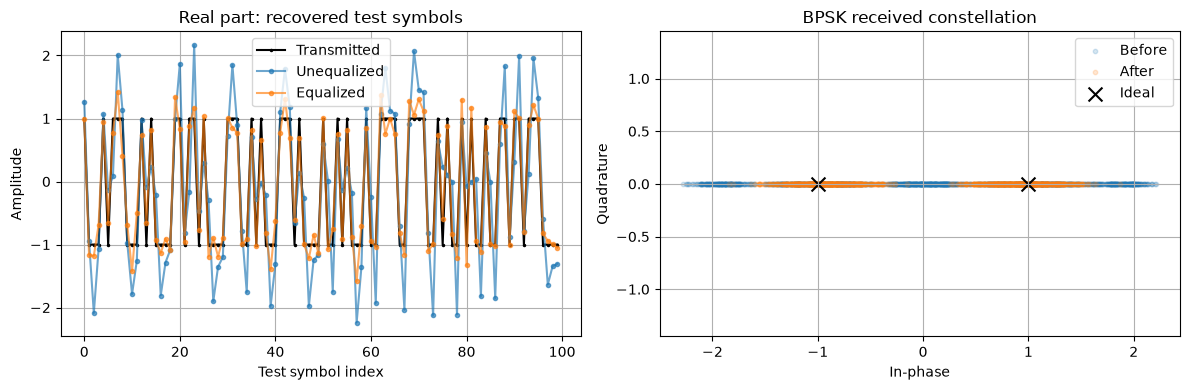

In [12]:
show_n = min(100, len(result["reference"]))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(np.real(result["reference"][:show_n]), "k.-", label="Transmitted", markersize=3)
axs[0].plot(np.real(result["baseline"][:show_n]), ".-", alpha=.65, label="Unequalized")
axs[0].plot(np.real(result["equalized"][:show_n]), ".-", alpha=.65, label="Equalized")
axs[0].set(title="Real part: recovered test symbols", xlabel="Test symbol index", ylabel="Amplitude")
axs[0].legend()
plot_n = min(1500, len(result["reference"]))
axs[1].scatter(result["baseline"][:plot_n].real, result["baseline"][:plot_n].imag,
               alpha=.18, s=10, label="Before")
axs[1].scatter(result["equalized"][:plot_n].real, result["equalized"][:plot_n].imag,
               alpha=.18, s=10, label="After")
axs[1].scatter(np.unique(result["reference"]).real, np.unique(result["reference"]).imag,
               marker="x", s=100, color="black", label="Ideal")
axs[1].set(title=f"{MODULATION} received constellation", xlabel="In-phase", ylabel="Quadrature")
axs[1].axis("equal"); axs[1].legend()
plt.tight_layout(); plt.show()

BPSK  | BER without LMS: 0.05569 | BER with LMS: 0.00008 | test MSE: 0.0773
QPSK  | BER without LMS: 0.05839 | BER with LMS: 0.00025 | test MSE: 0.0798


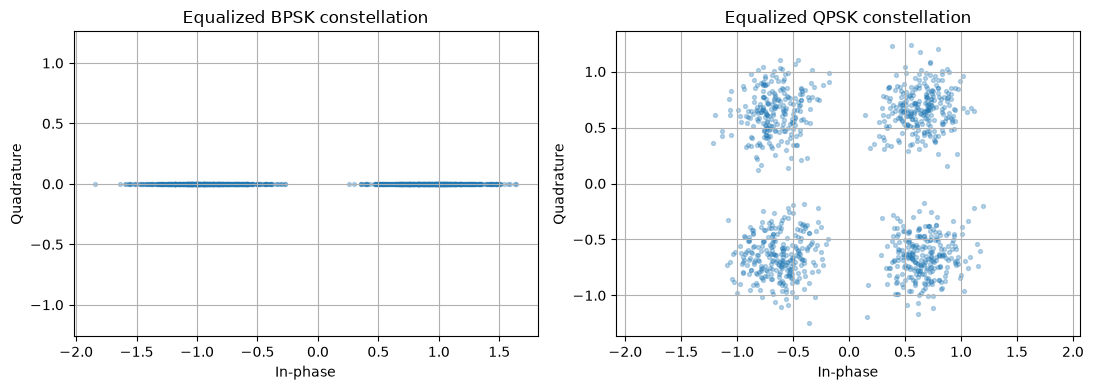

In [13]:
mod_results = {}
for scheme in ("BPSK", "QPSK"):
    r = simulate(scheme, SNR_DB, MU, NUM_TAPS, DECISION_DELAY,
                 CHANNEL, TRAIN_SYMBOLS, TEST_SYMBOLS, SEED)
    mod_results[scheme] = r
    print(f"{scheme:5s} | BER without LMS: {r['ber_before']:.5f} | "
          f"BER with LMS: {r['ber_after']:.5f} | test MSE: {r['mse_test_after']:.4f}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for a, scheme in zip(axs, ("BPSK", "QPSK")):
    r = mod_results[scheme]
    a.scatter(r["equalized"][:1000].real, r["equalized"][:1000].imag, s=8, alpha=.3)
    a.set(title=f"Equalized {scheme} constellation", xlabel="In-phase", ylabel="Quadrature")
    a.axis("equal")
plt.tight_layout(); plt.show()

SNR  4 dB | BER before = 0.15797 | after = 0.10012
SNR  8 dB | BER before = 0.1102 | after = 0.035428
SNR 12 dB | BER before = 0.087529 | after = 0.0078359
SNR 16 dB | BER before = 0.067022 | after = 0.00075025
SNR 20 dB | BER before = 0.042764 | after = 8.3361e-05


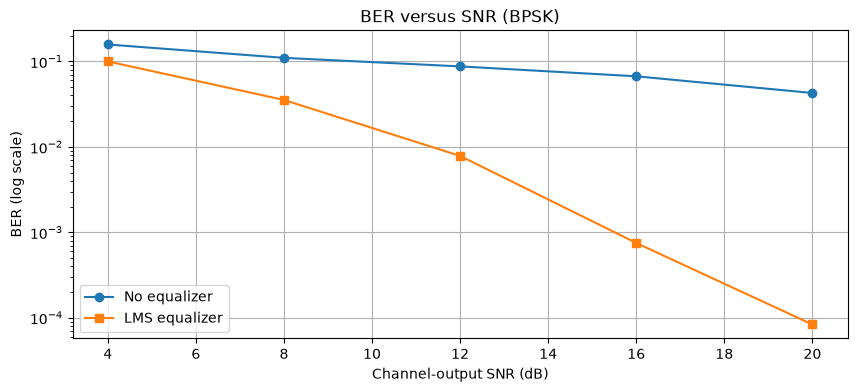

Note: zero counts appear at the one-error floor on the log plot.


In [14]:
snr_values = [4, 8, 12, 16, 20]
ber_before, ber_after = [], []
for snr in snr_values:
    r = simulate(MODULATION, snr, MU, NUM_TAPS, DECISION_DELAY,
                 CHANNEL, TRAIN_SYMBOLS, TEST_SYMBOLS, seed=SEED)
    ber_before.append(r["ber_before"])
    ber_after.append(r["ber_after"])
    print(f"SNR {snr:2d} dB | BER before = {r['ber_before']:.5g} | after = {r['ber_after']:.5g}")
fig, ax = plt.subplots()
# Display floor is only for log plotting; printed BER above uses actual counts.
plot_floor = 1 / (TEST_SYMBOLS * (2 if MODULATION == "QPSK" else 1))
ax.semilogy(snr_values, np.maximum(ber_before, plot_floor), "o-", label="No equalizer")
ax.semilogy(snr_values, np.maximum(ber_after, plot_floor), "s-", label="LMS equalizer")
ax.set(title=f"BER versus SNR ({MODULATION})", xlabel="Channel-output SNR (dB)", ylabel="BER (log scale)")
ax.legend(); plt.show()
print("Note: zero counts appear at the one-error floor on the log plot.")

##  Step-size sweep: convergence and misadjustment
Try smaller and larger step sizes. High step sizes can converge faster but may have larger residual error or even diverge. Settings shown below are chosen for safe comparison with the default channel.

mu=0.002 | final training MSE=0.07627 | test BER=8.33611e-05
mu=0.007 | final training MSE=0.07809 | test BER=8.33611e-05
mu=0.015 | final training MSE=0.08506 | test BER=8.33611e-05
mu=0.030 | final training MSE=0.10126 | test BER=8.33611e-05


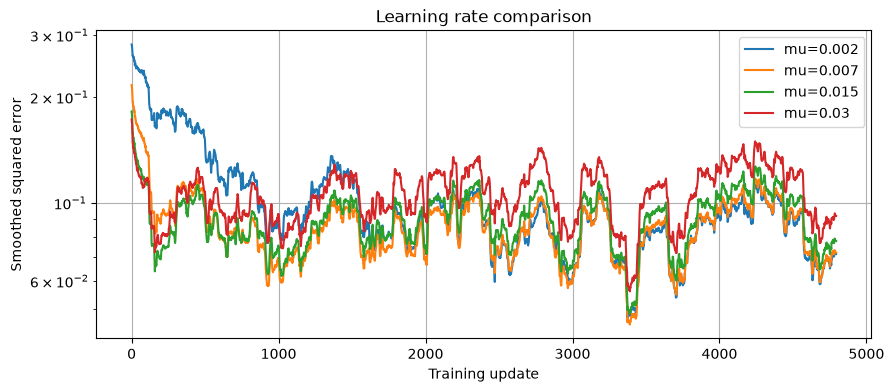

In [15]:
step_sizes = [0.002, 0.007, 0.015, 0.03]
fig, ax = plt.subplots()
for step in step_sizes:
    r = simulate(MODULATION, SNR_DB, step, NUM_TAPS, DECISION_DELAY,
                 CHANNEL, TRAIN_SYMBOLS, TEST_SYMBOLS, seed=SEED)
    loss = r["mse_history"]
    smooth = np.convolve(loss, np.ones(200)/200, "valid")
    ax.semilogy(np.arange(len(smooth)), np.maximum(smooth, 1e-9), label=f"mu={step}")
    print(f"mu={step:.3f} | final training MSE={loss[-500:].mean():.5f} | "
          f"test BER={r['ber_after']:.6g}")
ax.set(title="Learning rate comparison", xlabel="Training update", ylabel="Smoothed squared error")
ax.legend(); plt.show()

taps= 5 | test MSE=0.17362 | BER=0.0124208
taps= 7 | test MSE=0.12502 | BER=0.00275092
taps=11 | test MSE=0.07733 | BER=8.33611e-05
taps=15 | test MSE=0.06291 | BER=8.33611e-05
taps=21 | test MSE=0.05932 | BER=0


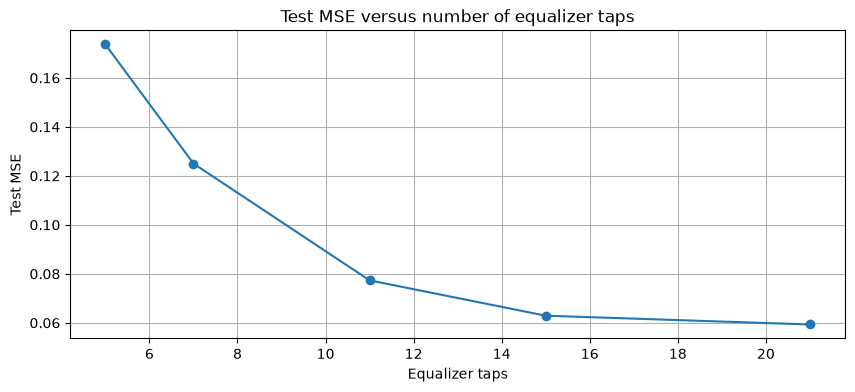

In [16]:
tap_options = [5, 7, 11, 15, 21]
length_mse, length_ber = [], []
for taps in tap_options:
    r = simulate(MODULATION, SNR_DB, MU, taps, DECISION_DELAY,
                 CHANNEL, TRAIN_SYMBOLS, TEST_SYMBOLS, seed=SEED)
    length_mse.append(r["mse_test_after"])
    length_ber.append(r["ber_after"])
    print(f"taps={taps:2d} | test MSE={r['mse_test_after']:.5f} | BER={r['ber_after']:.6g}")
fig, ax = plt.subplots()
ax.plot(tap_options, length_mse, "o-")
ax.set(title="Test MSE versus number of equalizer taps", xlabel="Equalizer taps", ylabel="Test MSE")
plt.show()

In [17]:
channel_cases = {
    "No ISI": [1.0],
    "Moderate ISI": [0.9, 0.50, -0.30],
    "Severe ISI": [0.65, 0.8, -0.45, 0.25],
}
channel_test_results = {}
for label, h in channel_cases.items():
    r = simulate(MODULATION, SNR_DB, MU, NUM_TAPS, DECISION_DELAY,
                 h, TRAIN_SYMBOLS, TEST_SYMBOLS, SEED)
    channel_test_results[label] = r
    print(f"{label:14s}: BER before={r['ber_before']:.5f}, "
          f"BER after={r['ber_after']:.5f}, test MSE after={r['mse_test_after']:.5f}")

No ISI        : BER before=0.00000, BER after=0.00000, test MSE after=0.01695
Moderate ISI  : BER before=0.05569, BER after=0.00008, test MSE after=0.07733
Severe ISI    : BER before=0.29110, BER after=0.00000, test MSE after=0.02656


In [18]:
# Unit checks
for scheme in ("BPSK", "QPSK"):
    b, s = generate_symbols(scheme, 100, np.random.default_rng(123))
    assert np.array_equal(bits_from_symbols(s, scheme), b)
    assert np.isclose(np.mean(np.abs(s)**2), 1.0)
assert np.allclose(channel_fir(np.array([1, 0, 0], complex), [1, 2, 3]), [1, 2, 3])
assert np.array_equal(tapped_input(np.arange(7), 4, 3), [4, 3, 2])
check1 = simulate("BPSK", seed=17)
check2 = simulate("BPSK", seed=17)
assert np.allclose(check1["weights"], check2["weights"])
assert check1["num_test_symbols"] == 12000 - check1["delay"]
assert np.isfinite(check1["mse_test_after"])
assert 0 <= check1["ber_after"] <= 1
print("PASS — mapper/demapper, channel, input window, test alignment, reproducibility, finite outputs")
print("\nCURRENT BASELINE RESULTS")
print(f"Modulation: {MODULATION} | channel: {CHANNEL} | SNR: {SNR_DB} dB")
print(f"Training: {TRAIN_SYMBOLS} | evaluated: {result['num_test_symbols']}")
print(f"BER before: {result['ber_before']:.6g} | BER after: {result['ber_after']:.6g}")
print(f"MSE before: {result['mse_test_before']:.6g} | MSE after: {result['mse_test_after']:.6g}")

PASS — mapper/demapper, channel, input window, test alignment, reproducibility, finite outputs

CURRENT BASELINE RESULTS
Modulation: BPSK | channel: [ 0.9+0.j  0.5+0.j -0.3+0.j] | SNR: 18.0 dB
Training: 5000 | evaluated: 11996
BER before: 0.0556852 | BER after: 8.33611e-05
MSE before: 0.439415 | MSE after: 0.0773341
